<a href="https://colab.research.google.com/github/DanielFelipeRuizBermudez/Proyecto-ALTILLANURA/blob/main/notebooks/60_integracion/61_correlaciones_espaciales.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 61 · Correlaciones espaciales entre fuego, lluvia, suelo y expansión (celdas de 2 km)

**Autoras:** Katalina y Michelle

**Pregunta:** en la misma unidad espacial (celdas de 2 km), ¿cómo se relacionan el fuego, la lluvia de la temporada seca, la acidez del suelo y la expansión agropecuaria? En particular, la hipótesis planteada por el profesor: **¿las zonas más ácidas, como Cumaribo, tienen menos focos de calor?**

**Entradas** (`datos/comunes/`, todas con la llave `id_celda`):

| Archivo | Cuaderno | Variables que se usan |
|---|---|---|
| `grilla_2km.gpkg` | 02 (Daniel) | geometría, municipio, `area_km2`, `frac_celda` |
| `focos_celda.csv` | 22 (Michelle) | `focos_km2_anio`, `focos_temporada_seca_media` |
| `lluvia_celda.csv` | 12 (Michelle) | `lluvia_anual_1991_2020`, `lluvia_seca_1991_2020` |
| `suelo_celda.csv` | 42 (Katalina) | `ph_medio`, `cos_medio_gkg`, `pct_area_ph_menor_5`, `clase_ph` |
| `quema_celda.csv` | 24 (Jonatan) | `quema_media_anual_pct` |
| `agro_celda.csv` | 30 (Daniel) | `agro_pct_2024`, `cambio_agro_pp`, `celda_valida` |

Las seis capas son **obligatorias**: si alguna no se puede bajar de DVC, el cuaderno se detiene con un error en vez de seguir sin ella, para que los resultados no cambien sin aviso.

**Salidas:** `modulos/integracion/resultados/61_*.csv` y `modulos/integracion/graficas/61_*.png`.

**Métodos:** correlación de Spearman con significancia corregida por autocorrelación espacial (tamaño de muestra efectivo de Clifford, Richardson y Hémon, 1989) y por comparaciones múltiples (Holm, 1979), comparación por clase de pH, Moran global y LISA bivariado (Anselin, 1995) con 999 permutaciones.

## Paso 1. Preparar el entorno

In [1]:
# Rutas del proyecto: funcionan en Colab y en local (ver 00_configuracion)
import os, sys, subprocess
EN_COLAB = 'google.colab' in sys.modules
REPO = 'https://github.com/DanielFelipeRuizBermudez/Proyecto-ALTILLANURA.git'

if EN_COLAB:
    try:   # este cuaderno no usa Drive; si el permiso falla, sigue
        from google.colab import drive
        drive.mount('/content/drive')
    except Exception as e:
        print('Drive no montado (este cuaderno no lo necesita):', e)
    # Los datos crudos pesados (MGN, CSV de FIRMS, copia del ONI) siguen en Drive
    CRUDOS = '/content/drive/MyDrive/proyecto-altillanura-STDG/datos/crudos'
    RAIZ = '/content/Proyecto-ALTILLANURA'
    if not os.path.exists(RAIZ):
        !git clone -q {REPO} {RAIZ}
    # Mientras el PR #3 no esté unido a main, los datos comunes están en esta rama
    if not os.path.exists(f'{RAIZ}/datos/comunes/oni_mensual.csv'):
        !git -C {RAIZ} fetch -q origin feature/clima-fuego-datos
        !git -C {RAIZ} checkout -q feature/clima-fuego-datos
else:
    RAIZ = os.path.abspath(os.path.join('..', '..'))   # el cuaderno está en notebooks/<etapa>/
    CRUDOS = os.path.join(RAIZ, 'datos', 'crudos')

COMUNES = os.path.join(RAIZ, 'datos', 'comunes')
GRAFICAS = os.path.join(RAIZ, 'modulos', 'clima_fuego', 'graficas')
os.makedirs(GRAFICAS, exist_ok=True)

def traer(ruta):
    """Baja de DVC un archivo pesado del repo (por ejemplo un .gpkg) si todavía no está."""
    if os.path.exists(os.path.join(RAIZ, ruta)):
        return
    if EN_COLAB:
        from google.colab import auth
        auth.authenticate_user()
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'dvc[gs]'], check=True)
    subprocess.run([sys.executable, '-m', 'dvc', 'pull', '-q', ruta], cwd=RAIZ, check=True)
    print('Bajado de DVC:', ruta)

print('Raíz del repo:', RAIZ)
print('Crudos:', CRUDOS, '| existe:', os.path.exists(CRUDOS))

RES_INT = os.path.join(RAIZ, 'modulos', 'integracion', 'resultados')
GRAF_INT = os.path.join(RAIZ, 'modulos', 'integracion', 'graficas')
os.makedirs(RES_INT, exist_ok=True)
os.makedirs(GRAF_INT, exist_ok=True)

try:
    import esda, libpysal
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'esda', 'libpysal'], check=True)
    import esda, libpysal

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.spatial import cKDTree
SEMILLA = 2026
print('esda', esda.__version__, '| libpysal', libpysal.__version__)

Raíz del repo: C:\Proyectos2026-2\Proyecto-ALTILLANURA
Crudos: C:\Proyectos2026-2\Proyecto-ALTILLANURA\datos\crudos | existe: False


esda 2.10.0 | libpysal 4.15.1


## Paso 2. Unir las capas por `id_celda`

Todas las capas se unen a la grilla con `validate='one_to_one'`, que falla si algún `id_celda` está repetido.

**Qué celdas se analizan:**
1. Solo las que tienen al menos la mitad de su área dentro de la región (`frac_celda` ≥ 0,5). En las celdas de borde muy pequeñas un solo foco produce densidades extremas (por ejemplo, 1 foco en 0,14 km²), y esos valores distorsionarían las correlaciones.
2. Solo las que tienen `celda_valida = True` en `agro_celda.csv`: los mapas de MapBiomas de 2000 y 2024 tienen dato en al menos la mitad de la celda. Así el % agropecuario no se calcula sobre unos pocos píxeles.

In [2]:
CAPAS = ['grilla_2km.gpkg', 'focos_celda.csv', 'lluvia_celda.csv', 'suelo_celda.csv',
         'quema_celda.csv', 'agro_celda.csv']
for f in CAPAS:                         # todas obligatorias: si falla dvc pull, el cuaderno se detiene
    traer(f'datos/comunes/{f}')
    assert os.path.exists(f'{COMUNES}/{f}'), f'Falta datos/comunes/{f}: revisa dvc pull'

grilla = gpd.read_file(f'{COMUNES}/grilla_2km.gpkg')
leer = lambda f: pd.read_csv(f'{COMUNES}/{f}', dtype={'id_celda': str, 'mpio_cdpmp': str})
d = grilla.merge(leer('focos_celda.csv'), on='id_celda', how='left', validate='one_to_one')
d = d.merge(leer('lluvia_celda.csv'), on='id_celda', how='left', validate='one_to_one')
suelo = leer('suelo_celda.csv').drop(columns=['mpio_cdpmp', 'area_km2'], errors='ignore')
d = d.merge(suelo, on='id_celda', how='left', validate='one_to_one')

VARIABLES = {
    'focos_km2_anio': 'Focos por km² al año (FIRMS)',
    'lluvia_seca_1991_2020': 'Lluvia de dic–mar (mm)',
    'lluvia_anual_1991_2020': 'Lluvia anual (mm)',
    'ph_medio': 'pH del suelo',
    'cos_medio_gkg': 'Carbono orgánico (g/kg)',
}
for archivo, cols in [('quema_celda.csv', {'quema_media_anual_pct': 'Área quemada al año (%, MapBiomas)'}),
                      ('agro_celda.csv', {'agro_pct_2024': '% agropecuario 2024',
                                          'cambio_agro_pp': 'Cambio agropecuario 2000–2024 (pp)'})]:
    capa = leer(archivo)
    capa = capa.drop(columns=[c for c in capa.columns if c in d.columns and c != 'id_celda'] + ['n_pixeles'], errors='ignore')
    faltan_cols = [c for c in cols if c not in capa.columns]
    assert not faltan_cols, f'{archivo} no tiene las columnas {faltan_cols}'
    d = d.merge(capa, on='id_celda', how='left', validate='one_to_one')
    VARIABLES.update(cols)
    print('Capa incluida:', archivo)

d['x_km'] = d['id_celda'].str.extract(r'x(\d+)_')[0].astype(int)
d['y_km'] = d['id_celda'].str.extract(r'_y(\d+)')[0].astype(int)
d = d[d['frac_celda'] >= 0.5].reset_index(drop=True)
print(f'\nCeldas con frac_celda ≥ 0,5: {len(d):,} de {len(grilla):,}')
valida = d['celda_valida'].astype(str).str.strip().str.lower().eq('true')
print(f'Celdas excluidas por celda_valida = False (agro_celda): {(~valida).sum():,}')
if (~valida).any():
    print(d.loc[~valida, 'mpio_cnmbr'].value_counts().to_string())
d = d[valida].reset_index(drop=True)
faltan = d[list(VARIABLES)].isna().sum()
print(f'Celdas analizadas: {len(d):,}')
print('Valores faltantes por variable:'); print(faltan.to_string())
d = d.dropna(subset=list(VARIABLES)).reset_index(drop=True)
print(f'Celdas con todas las variables: {len(d):,}')

Capa incluida: quema_celda.csv
Capa incluida: agro_celda.csv



Celdas con frac_celda ≥ 0,5: 33,913 de 34,763
Celdas excluidas por celda_valida = False (agro_celda): 114
mpio_cnmbr
PUERTO CARREÑO    62
LA PRIMAVERA      30
CUMARIBO          22
Celdas analizadas: 33,799
Valores faltantes por variable:
focos_km2_anio            0
lluvia_seca_1991_2020     0
lluvia_anual_1991_2020    0
ph_medio                  0
cos_medio_gkg             0
quema_media_anual_pct     0
agro_pct_2024             0
cambio_agro_pp            0
Celdas con todas las variables: 33,799


## Paso 3. Correlaciones de Spearman con significancia corregida

**Por qué hay que corregir.** Una correlación entre ~33.000 celdas casi siempre sale "significativa" con la prueba usual, porque esa prueba supone que cada celda es una observación independiente. Pero celdas vecinas se parecen (la lluvia de CHIRPS, por ejemplo, viene de píxeles de ~5 km): la **información real** equivale a muchas menos observaciones.

**Cómo se corrige (Clifford, Richardson y Hémon, 1989).** Se estima un **tamaño de muestra efectivo** $n_{ef}$:

1. Se pasan las dos variables a rangos (Spearman) y se estandarizan: $z_x$, $z_y$.
2. Con una muestra aleatoria de 4.000 celdas se calcula, para clases de distancia de 10 km, la autocorrelación de cada variable: $\hat\rho_x(k)$ = promedio de $z_{x,i}\,z_{x,j}$ entre los pares de celdas en la clase $k$ (lo mismo para $y$).
3. La varianza de la correlación bajo la hipótesis de no relación es aproximadamente

$$\operatorname{Var}(r) \approx \frac{1}{n} + \frac{n-1}{n}\sum_k p_k\,\hat\rho_x(k)\,\hat\rho_y(k)$$

donde $p_k$ es la proporción de pares de celdas en la clase $k$. Si las variables no tienen autocorrelación, $\operatorname{Var}(r) = 1/n$, como en la prueba usual.

4. $n_{ef} = 1/\operatorname{Var}(r)$ y la prueba usa $t = r\sqrt{(n_{ef}-2)/(1-r^2)}$ con $n_{ef} - 2$ grados de libertad.

Así, una correlación con miles de celdas puede resultar no significativa si las dos variables tienen gradientes regionales suaves: de ellas solo hay unas pocas "observaciones independientes".

**Estabilidad del $n_{ef}$.** Como se estima con una muestra aleatoria de celdas y de pares, cambia un poco de una muestra a otra (~10 %). Para que no dependa de una sola muestra, el cálculo se repite **10 veces** con muestras distintas y se promedia $\operatorname{Var}(r)$. La tabla guarda el rango (`n_efectivo_min`, `n_efectivo_max`): el $n_{ef}$ se reporta como **aproximado**.

**Comparaciones múltiples (Holm, 1979).** Con 8 variables hay 28 pares. Si se prueba cada uno con α = 0,05, es esperable que alguno salga "significativo" por azar. El método de Holm ordena los p-valores de menor a mayor y compara el k-ésimo con 0,05/(28 − k + 1): así la probabilidad de **al menos un** falso positivo en toda la tabla queda en 5 %. La columna `p_holm` es el p-valor ajustado:
- `p_holm` < 0,05 → **significativa** (asterisco en la matriz);
- `p_corregido` < 0,05 pero `p_holm` ≥ 0,05 → **indicativa**: resiste la autocorrelación, pero no la corrección por comparaciones múltiples.

33,799 celdas | 8 variables | 28 pares | n efectivo promediado en 10 repeticiones

            variable_1             variable_2  spearman  n_efectivo  n_efectivo_min  n_efectivo_max  p_corregido  p_sin_corregir  p_holm        resultado
        focos_km2_anio  quema_media_anual_pct     0.818        38.0            34.0            43.0       0.0000             0.0  0.0000    significativa
         agro_pct_2024         cambio_agro_pp     0.706        52.0            44.0            61.0       0.0000             0.0  0.0000    significativa
              ph_medio  quema_media_anual_pct     0.737        24.0            22.0            27.0       0.0000             0.0  0.0010    significativa
        focos_km2_anio               ph_medio     0.615        29.0            27.0            33.0       0.0004             0.0  0.0090    significativa
        focos_km2_anio         cambio_agro_pp     0.404        70.0            60.0            79.0       0.0005             0.0  0.0130    signifi

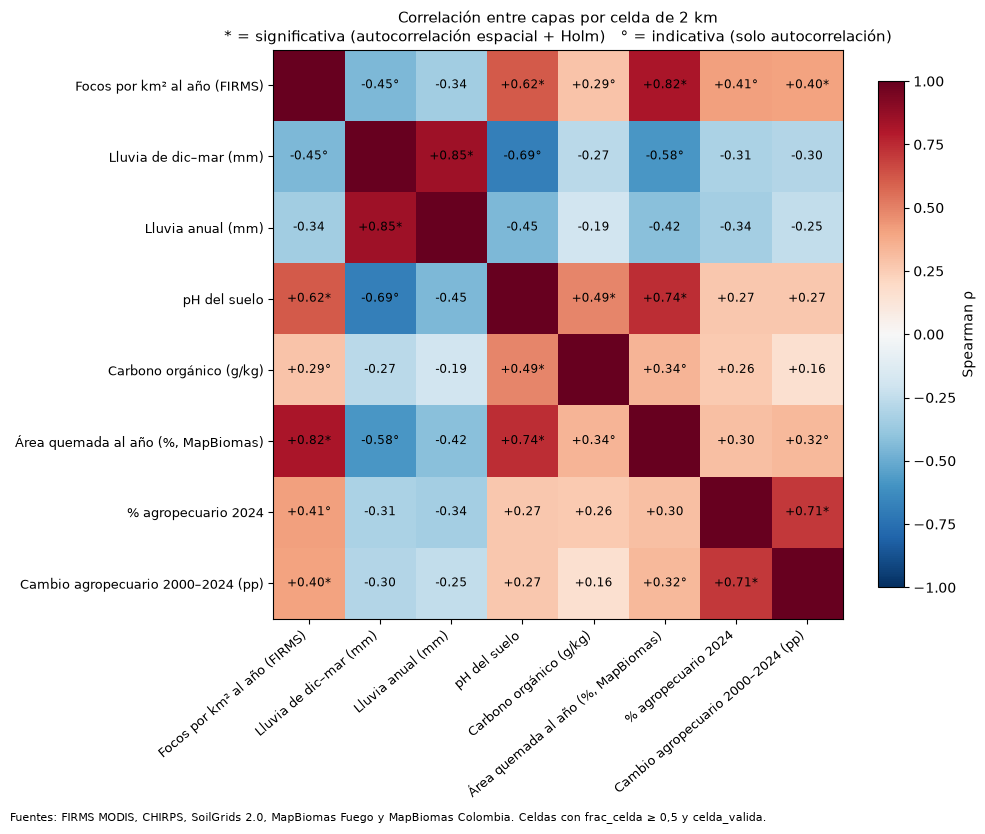

In [3]:
REPETICIONES, M_CELDAS, N_PARES = 10, 4000, 2_000_000
rng = np.random.default_rng(SEMILLA)
nombres = list(VARIABLES)
n = len(d)
xy_todas = d[['x_km', 'y_km']].to_numpy(float)
Z = {}
for v in nombres:
    z = stats.rankdata(d[v].to_numpy()); Z[v] = (z - z.mean()) / z.std()

def una_repeticion():
    """Var(r) de Clifford para todos los pares, con una muestra aleatoria de celdas y de pares."""
    m = min(M_CELDAS, n)
    muestra = rng.choice(n, m, replace=False)
    xy = xy_todas[muestra]
    i = rng.integers(0, m, N_PARES); j = rng.integers(0, m, N_PARES)
    ok = i != j; i, j = i[ok], j[ok]
    clase = np.minimum((np.hypot(*(xy[i] - xy[j]).T) // 10).astype(int), 59)   # clases de 10 km hasta 600 km
    cuenta = np.bincount(clase, minlength=60)
    p_k = cuenta / len(clase)
    rho = {}
    for v in nombres:
        zm = Z[v][muestra]
        suma = np.bincount(clase, weights=zm[i] * zm[j], minlength=60)
        rho[v] = np.divide(suma, cuenta, out=np.zeros(60), where=cuenta > 0)
    return {(a, b): 1 / n + (n - 1) / n * np.sum(p_k * rho[a] * rho[b])
            for a_i, a in enumerate(nombres) for b in nombres[a_i + 1:]}

VAR_R = [una_repeticion() for _ in range(REPETICIONES)]

filas = []
for a_i, a in enumerate(nombres):
    for b in nombres[a_i + 1:]:
        r = stats.spearmanr(d[a], d[b])[0]
        varios = np.maximum([vr[(a, b)] for vr in VAR_R], 1 / n)   # Var(r) no puede ser menor que sin autocorrelación
        n_ef = float(np.clip(1 / varios.mean(), 3, n))
        n_ef_rep = np.clip(1 / varios, 3, n)
        t = r * np.sqrt((n_ef - 2) / (1 - r ** 2))
        p = 2 * stats.t.sf(abs(t), n_ef - 2)
        p_ingenuo = 2 * stats.t.sf(abs(r * np.sqrt((n - 2) / (1 - r ** 2))), n - 2)
        filas.append({'variable_1': a, 'variable_2': b, 'spearman': r, 'n_celdas': n,
                      'n_efectivo': n_ef, 'n_efectivo_min': n_ef_rep.min(), 'n_efectivo_max': n_ef_rep.max(),
                      'p_corregido': p, 'p_sin_corregir': p_ingenuo})
corr = pd.DataFrame(filas)

# Holm: p ajustado = máximo acumulado de (k pruebas restantes) × p, ordenado de menor a mayor
orden_p = np.argsort(corr['p_corregido'].to_numpy())
k = len(corr)
ajust = np.minimum(1, np.maximum.accumulate((k - np.arange(k)) * corr['p_corregido'].to_numpy()[orden_p]))
corr['p_holm'] = np.empty(k); corr.loc[orden_p, 'p_holm'] = ajust
corr['resultado'] = np.select([corr['p_holm'] < 0.05, corr['p_corregido'] < 0.05],
                              ['significativa', 'indicativa'], 'no significativa')
corr = corr.sort_values('p_corregido').reset_index(drop=True)

print(f'{n:,} celdas | {len(nombres)} variables | {k} pares | n efectivo promediado en {REPETICIONES} repeticiones\n')
print(corr.round({'spearman': 3, 'n_efectivo': 0, 'n_efectivo_min': 0, 'n_efectivo_max': 0,
                  'p_corregido': 4, 'p_holm': 4, 'p_sin_corregir': 4})
          .drop(columns='n_celdas').to_string(index=False))
print('\nResumen:', corr['resultado'].value_counts().to_dict())

mat = pd.DataFrame(np.eye(len(nombres)), index=nombres, columns=nombres)
for _, f in corr.iterrows():
    mat.loc[f.variable_1, f.variable_2] = mat.loc[f.variable_2, f.variable_1] = f.spearman
MARCA = {'significativa': '*', 'indicativa': '°', 'no significativa': ''}
sig = {(f.variable_1, f.variable_2): MARCA[f.resultado] for _, f in corr.iterrows()}
fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(mat, cmap='RdBu_r', vmin=-1, vmax=1)
etiq = [VARIABLES[v] for v in nombres]
ax.set_xticks(range(len(nombres)), etiq, rotation=40, ha='right', fontsize=9)
ax.set_yticks(range(len(nombres)), etiq, fontsize=9)
for a_i, a in enumerate(nombres):
    for b_i, b in enumerate(nombres):
        if a_i != b_i:
            s = sig.get((a, b), sig.get((b, a)))
            ax.text(b_i, a_i, f'{mat.iloc[a_i, b_i]:+.2f}{s}', ha='center', va='center', fontsize=8.5)
plt.colorbar(im, ax=ax, shrink=0.8, label='Spearman ρ')
ax.set_title('Correlación entre capas por celda de 2 km\n* = significativa (autocorrelación espacial + Holm)   ° = indicativa (solo autocorrelación)', fontsize=11)
fig.text(0.01, 0.01, 'Fuentes: FIRMS MODIS, CHIRPS, SoilGrids 2.0, MapBiomas Fuego y MapBiomas Colombia. Celdas con frac_celda ≥ 0,5 y celda_valida.', fontsize=8)
plt.tight_layout()
plt.savefig(f'{GRAF_INT}/61_matriz_correlacion.png', dpi=150, bbox_inches='tight')
plt.show()

## Paso 4. Comparación por clase de acidez y la hipótesis de Cumaribo

En la Altillanura casi no hay suelos alcalinos: la comparación útil es entre grados de acidez (clases del cuaderno 42). Para cada clase se resume la mediana de cada variable. Es una tabla **descriptiva**: las celdas de una misma clase están agrupadas en el espacio, así que no se le aplica una prueba que suponga independencia; la prueba formal es la del paso 3 y el LISA del paso 5.

Además se compara **Cumaribo frente al resto** de la región, que es la forma concreta de la hipótesis del profesor.

Mediana por clase de pH:
                                  focos_km2_anio  lluvia_seca_1991_2020  lluvia_anual_1991_2020  ph_medio  cos_medio_gkg  quema_media_anual_pct  agro_pct_2024  cambio_agro_pp  celdas
clase_ph                                                                                                                                                                              
extremadamente acido (<4.5)                 0.00                 461.00                 3075.70      4.49          19.84                   0.00           0.00            0.00      74
muy fuertemente acido (4.5-5.0)             0.00                 415.00                 2897.82      4.75          17.15                   0.00           0.00            0.00   11470
fuertemente acido (5.1-5.5)                 0.09                 264.30                 2675.72      5.14          19.73                  16.61           5.41            2.47   22246
moderadamente acido o mas (>5.5)            0.07            

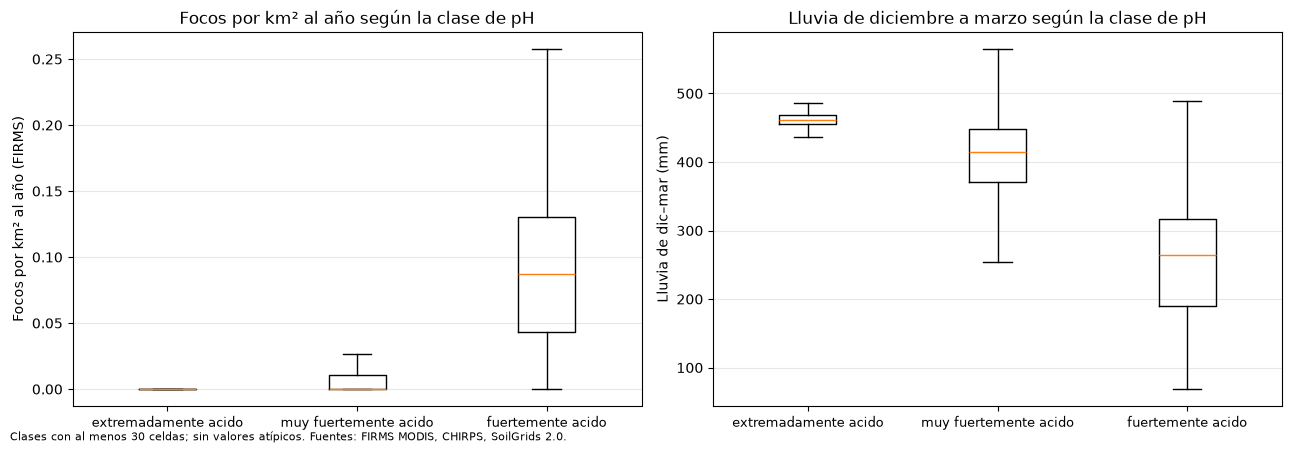

In [4]:
orden = ['extremadamente acido (<4.5)', 'muy fuertemente acido (4.5-5.0)',
         'fuertemente acido (5.1-5.5)', 'moderadamente acido o mas (>5.5)']
por_clase = (d.groupby('clase_ph')[nombres].median()
             .join(d.groupby('clase_ph').size().rename('celdas'))
             .reindex([c for c in orden if c in d['clase_ph'].unique()]))
print('Mediana por clase de pH:'); print(por_clase.round(2).to_string())

d['zona'] = np.where(d['mpio_cnmbr'].str.upper().str.contains('CUMARIBO'), 'Cumaribo', 'Resto de la Altillanura')
por_zona = d.groupby('zona')[nombres].median().join(d.groupby('zona').size().rename('celdas'))
print('\nMediana Cumaribo vs. resto:'); print(por_zona.round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
clases_presentes = [c for c in orden if (d['clase_ph'] == c).sum() >= 30]
for ax, v in zip(axes, ['focos_km2_anio', 'lluvia_seca_1991_2020']):
    datos = [d.loc[d['clase_ph'] == c, v] for c in clases_presentes]
    ax.boxplot(datos, showfliers=False)
    ax.set_xticks(range(1, len(clases_presentes) + 1), [c.split(' (')[0] for c in clases_presentes], fontsize=9)
    ax.set_ylabel(VARIABLES[v]); ax.grid(alpha=0.3, axis='y')
axes[0].set_title('Focos por km² al año según la clase de pH')
axes[1].set_title('Lluvia de diciembre a marzo según la clase de pH')
fig.text(0.01, 0.01, 'Clases con al menos 30 celdas; sin valores atípicos. Fuentes: FIRMS MODIS, CHIRPS, SoilGrids 2.0.', fontsize=8)
plt.tight_layout()
plt.savefig(f'{GRAF_INT}/61_por_clase_ph.png', dpi=150, bbox_inches='tight')
plt.show()

## Paso 5. Moran global y LISA bivariado

**Qué mide.** El **LISA bivariado** (Anselin, 1995) compara el valor de una variable en cada celda con el promedio de **otra** variable en sus vecinas. Para "focos vs. pH":

$$I_i^{BV} = z_{x,i} \sum_j w_{ij}\, z_{y,j}$$

con $x$ = focos por km² al año, $y$ = pH, ambos estandarizados, y $w_{ij}$ = pesos de vecindad (las 8 celdas que tocan a la celda $i$, normalizados para sumar 1). Cada celda significativa cae en un cuadrante:

| Cuadrante | Significado (focos vs. pH) |
|---|---|
| **Alto–Alto** | Muchos focos, rodeados de suelos menos ácidos |
| **Bajo–Bajo** | Pocos focos, rodeados de suelos más ácidos |
| **Alto–Bajo** | Muchos focos, rodeados de suelos más ácidos |
| **Bajo–Alto** | Pocos focos, rodeados de suelos menos ácidos |

**Significancia:** 999 permutaciones condicionales por celda (se reordenan al azar los valores de las vecinas). Se marcan las celdas con p < 0,05. Con decenas de miles de celdas habrá falsos positivos, así que el mapa se lee como **zonas** donde se concentran las celdas significativas, no celda por celda.

**Vecindad:** reina (queen), construida desde `id_celda`: dos celdas son vecinas si sus esquinas están a 2 km o menos en x y en y.

Se calcula para cinco pares: focos vs. pH, focos vs. lluvia de la temporada seca, focos vs. cambio agropecuario, pH vs. cambio agropecuario y área quemada vs. pH.

Celdas: 33,799 | vecinas promedio: 7.9 | sin vecinas: 0


focos_km2_anio vs. ph_medio: I bivariado = +0.521 (p = 0.001) | Alto–Alto: 7,210, Bajo–Alto: 4,834, Bajo–Bajo: 9,202, Alto–Bajo: 369


focos_km2_anio vs. lluvia_seca_1991_2020: I bivariado = -0.339 (p = 0.001) | Alto–Alto: 1,919, Bajo–Alto: 8,713, Bajo–Bajo: 4,505, Alto–Bajo: 5,311


focos_km2_anio vs. cambio_agro_pp: I bivariado = +0.146 (p = 0.001) | Alto–Alto: 2,457, Bajo–Alto: 2,296, Bajo–Bajo: 8,570, Alto–Bajo: 1,433


ph_medio vs. cambio_agro_pp: I bivariado = +0.173 (p = 0.001) | Alto–Alto: 4,088, Bajo–Alto: 665, Bajo–Bajo: 7,121, Alto–Bajo: 2,882


quema_media_anual_pct vs. ph_medio: I bivariado = +0.565 (p = 0.001) | Alto–Alto: 8,165, Bajo–Alto: 3,879, Bajo–Bajo: 9,558, Alto–Bajo: 13


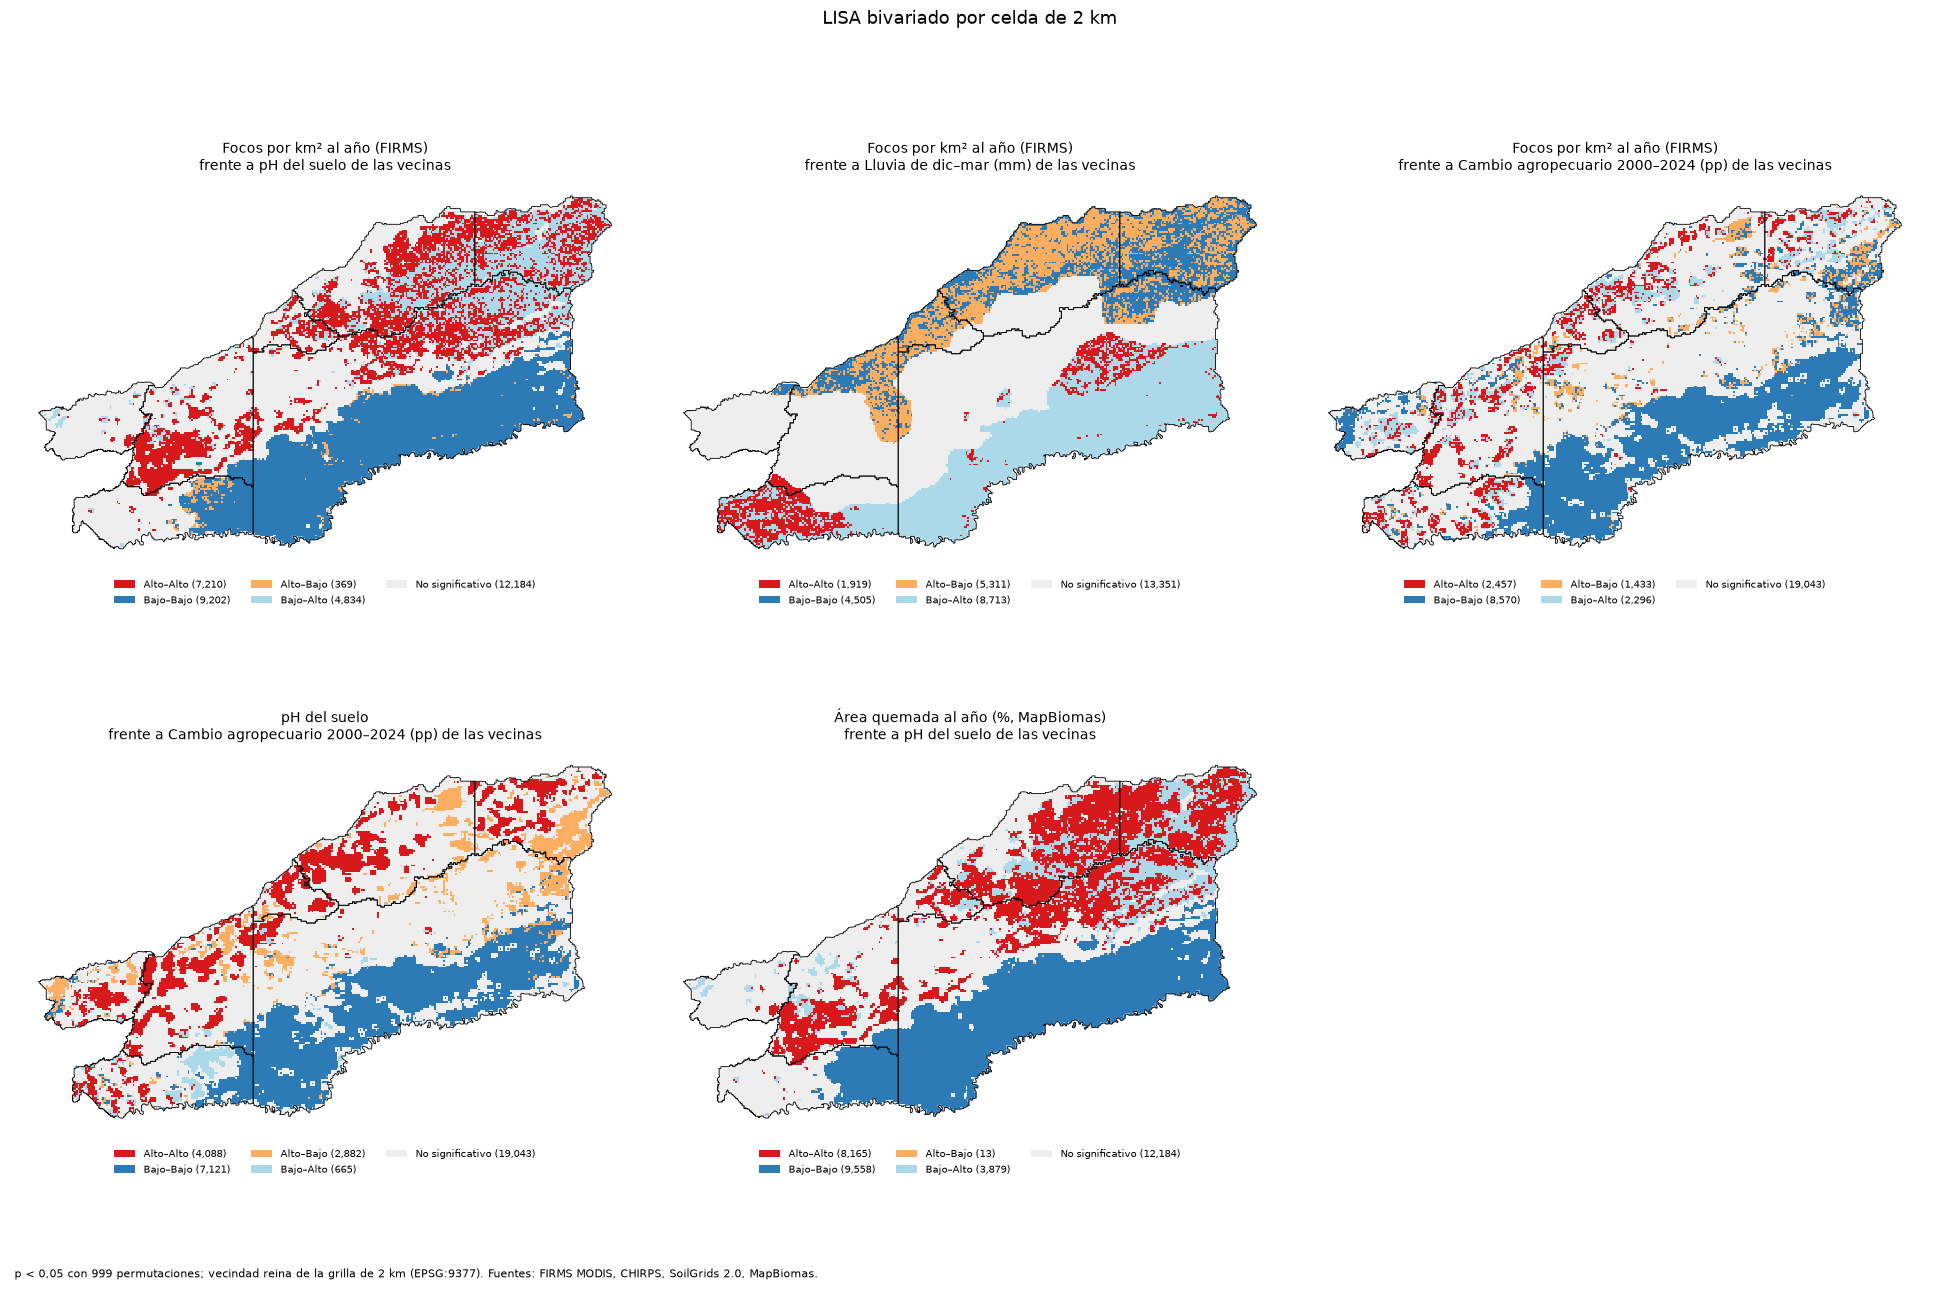


% de celdas de cada municipio por cuadrante (focos_km2_anio vs. ph_medio):
focos_km2_anio__ph_medio  Alto–Alto  Alto–Bajo  Bajo–Alto  Bajo–Bajo  No significativo
municipio                                                                             
CUMARIBO                       13.5        1.1       10.2       49.7              25.6
LA PRIMAVERA                   42.4        0.0       26.9        0.0              30.7
MAPIRIPÁN                       1.5        6.5        0.5       31.8              59.7
PUERTO CARREÑO                 41.8        0.0       52.1        0.0               6.1
PUERTO GAITÁN                  32.6        0.1        4.2        3.7              59.3
PUERTO LÓPEZ                    4.3        0.0        5.8        0.0              89.9
SANTA ROSALÍA                  32.7        0.0       11.2        0.0              56.1


In [5]:
pos = {(x, y): k for k, (x, y) in enumerate(zip(d['x_km'], d['y_km']))}
vecinos = {k: [pos[(x + dx, y + dy)] for dx in (-2, 0, 2) for dy in (-2, 0, 2)
               if (dx or dy) and (x + dx, y + dy) in pos]
           for (x, y), k in pos.items()}
aisladas = [k for k, v in vecinos.items() if not v]
w = libpysal.weights.W(vecinos, silence_warnings=True)
w.transform = 'r'
print(f'Celdas: {w.n:,} | vecinas promedio: {w.mean_neighbors:.1f} | sin vecinas: {len(aisladas)}')

PARES = [('focos_km2_anio', 'ph_medio'), ('focos_km2_anio', 'lluvia_seca_1991_2020'),
         ('focos_km2_anio', 'cambio_agro_pp'), ('ph_medio', 'cambio_agro_pp'),
         ('quema_media_anual_pct', 'ph_medio')]

ETIQ = {1: 'Alto–Alto', 2: 'Bajo–Alto', 3: 'Bajo–Bajo', 4: 'Alto–Bajo'}
glob, lisa = [], pd.DataFrame({'id_celda': d['id_celda']})
for x, y in PARES:
    gm = esda.Moran_BV(d[x].values, d[y].values, w, permutations=999)
    lm = esda.Moran_Local_BV(d[x].values, d[y].values, w, permutations=999, seed=SEMILLA)
    cuad = np.where(lm.p_sim < 0.05, lm.q, 0)
    lisa[f'{x}__{y}'] = pd.Series(cuad).map(ETIQ).fillna('No significativo').values
    conteo = lisa[f'{x}__{y}'].value_counts()
    glob.append({'x': x, 'y': y, 'I_bivariado': gm.I, 'p_permutacion': gm.p_sim,
                 **{f'celdas_{e}': int(conteo.get(e, 0)) for e in list(ETIQ.values()) + ['No significativo']}})
    print(f'{x} vs. {y}: I bivariado = {gm.I:+.3f} (p = {gm.p_sim:.3f}) | ' +
          ', '.join(f'{e}: {conteo.get(e, 0):,}' for e in ETIQ.values()))
glob = pd.DataFrame(glob)

colores = {'Alto–Alto': '#d7191c', 'Bajo–Bajo': '#2c7bb6', 'Alto–Bajo': '#fdae61',
           'Bajo–Alto': '#abd9e9', 'No significativo': '#eeeeee'}
mpios = d.dissolve(by='mpio_cnmbr')
ncol = int(np.ceil(len(PARES) / 2))
fig, axes = plt.subplots(2, ncol, figsize=(6.5 * ncol, 13), squeeze=False)
for ax, (x, y) in zip(axes.flat, PARES):
    col = lisa[f'{x}__{y}']
    for e, c in colores.items():
        sub = d[col.values == e]
        if len(sub):
            sub.plot(ax=ax, color=c, linewidth=0, label=f'{e} ({len(sub):,})')
    mpios.boundary.plot(ax=ax, color='black', linewidth=0.6)
    ax.set_title(f'{VARIABLES[x]}\nfrente a {VARIABLES[y]} de las vecinas', fontsize=10)
    ax.legend(fontsize=7.5, loc='upper center', bbox_to_anchor=(0.5, -0.01), ncol=3, frameon=False)
    ax.set_axis_off()
for ax in axes.flat[len(PARES):]:
    ax.set_visible(False)
fig.suptitle('LISA bivariado por celda de 2 km', fontsize=13)
fig.text(0.01, 0.005, 'p < 0,05 con 999 permutaciones; vecindad reina de la grilla de 2 km (EPSG:9377). '
         'Fuentes: FIRMS MODIS, CHIRPS, SoilGrids 2.0, MapBiomas.', fontsize=8)
plt.tight_layout(rect=(0, 0.02, 1, 0.97))
plt.savefig(f'{GRAF_INT}/61_lisa_bivariado.png', dpi=150, bbox_inches='tight')
plt.show()

por_mpio = (lisa.assign(municipio=d['mpio_cnmbr'].values)
            .groupby('municipio')[f'{PARES[0][0]}__{PARES[0][1]}'].value_counts(normalize=True)
            .mul(100).unstack(fill_value=0).round(1))
print(f'\n% de celdas de cada municipio por cuadrante ({PARES[0][0]} vs. {PARES[0][1]}):')
print(por_mpio.to_string())

### Cómo leer los resultados

- **Matriz de correlación (paso 3).** El signo dice la dirección; el asterisco (*), que la relación resiste la autocorrelación espacial y la corrección de Holm; el círculo (°), que solo resiste la autocorrelación y debe leerse como **indicativa**. Compara las columnas `p_corregido` y `p_sin_corregir`: la diferencia muestra cuánto inflaría la significancia ignorar que las celdas vecinas no son independientes. El `n_efectivo` indica a cuántas observaciones independientes equivalen las ~33.000 celdas.
- **Por clase de pH y Cumaribo (paso 4).** Si las celdas muy fuertemente ácidas y Cumaribo tienen una mediana de focos menor, el dato apoya la hipótesis del profesor de forma descriptiva.
- **LISA bivariado (paso 5).** Las zonas **Bajo–Bajo** (pocos focos junto a suelos más ácidos) en Cumaribo y Mapiripán, y **Alto–Alto** en el occidente o el norte, serían la versión espacial de esa hipótesis.

**Advertencias para el informe:**
1. **Correlación no es causa.** Que haya menos focos sobre suelos más ácidos puede deberse a otra variable que cambia en la misma dirección, como la lluvia de la temporada seca: el sur es a la vez más ácido y más lluvioso. Por eso la lluvia está en la matriz: si pH y lluvia de dic–mar están muy correlacionados, el efecto del pH no se puede separar del clima con correlaciones simples. Eso lo hace el modelo integrador (cuaderno 63).
2. **SoilGrids usa la cobertura del suelo como covariable**, así que la relación entre pH y uso agropecuario puede ser en parte circular.
3. **CHIRPS tiene un artefacto rectangular** en el nororiente (cuaderno 12); conviene repetir las correlaciones de lluvia sin esas celdas.
4. Los periodos no coinciden del todo: focos 2003–2025, lluvia normal 1991–2020, quema 2015–2025, agro 2000–2024, suelo sin fecha.
5. El $n_{ef}$ es una estimación por muestreo: se reporta como aproximado, con su rango en 10 repeticiones.

### Resultados y conclusiones

**Datos analizados.** 33.799 celdas: las que tienen al menos la mitad de su área en la región (`frac_celda` ≥ 0,5), menos 114 con `celda_valida = False` en la capa agropecuaria. Son 8 variables y 28 pares.

**1. La autocorrelación espacial y las comparaciones múltiples cambian la lectura.**
- Sin corregir, los 28 pares dan p = 0,0.
- Con la corrección de Clifford, las ~33.800 celdas equivalen a solo **~12 a ~93 observaciones independientes**, según el par. Es un valor aproximado: varía ~10 % entre las 10 repeticiones del muestreo (rango en `n_efectivo_min` y `n_efectivo_max`).
- Al aplicar además Holm a los 28 pares, quedan **7 relaciones significativas**, **7 indicativas** (resisten la autocorrelación pero no Holm) y **14 no significativas**.

| Relación | ρ de Spearman | n efectivo (aprox.) | p corregido | p Holm | Resultado |
|---|---|---|---|---|---|
| Focos FIRMS ↔ área quemada MapBiomas | **+0,82** | 38 | < 0,001 | < 0,001 | significativa |
| Área quemada ↔ pH | **+0,74** | 24 | < 0,001 | 0,001 | significativa |
| Focos ↔ pH | **+0,62** | 29 | < 0,001 | 0,009 | significativa |
| Focos ↔ cambio agropecuario 2000–2024 | **+0,40** | 70 | 0,001 | 0,013 | significativa |
| Focos ↔ % agropecuario 2024 | +0,41 | 42 | 0,007 | 0,14 | indicativa |
| Lluvia de dic–mar ↔ pH | −0,69 | 14 | 0,007 | 0,14 | indicativa |
| Lluvia de dic–mar ↔ área quemada | −0,58 | 20 | 0,007 | 0,14 | indicativa |
| Área quemada ↔ cambio agropecuario | +0,32 | 59 | 0,013 | 0,24 | indicativa |
| Focos ↔ lluvia de dic–mar | −0,45 | 25 | 0,025 | 0,39 | indicativa |
| pH ↔ cambio agropecuario (H4) | +0,27 | 42 | 0,078 | 0,86 | no significativa |
| pH ↔ % agropecuario 2024 | +0,27 | 24 | 0,21 | 0,86 | no significativa |

Las otras significativas son esperables y sirven de control: lluvia de dic–mar con lluvia anual (+0,85), % agropecuario 2024 con su cambio (+0,71) y pH con carbono orgánico (+0,49).

**2. Dos fuentes de fuego independientes coinciden.** Los focos de FIRMS (MODIS, 1 km, 2003–2025) y el área quemada de MapBiomas (Landsat, 30 m, 2015–2025) tienen ρ = +0,82. Ambas capas describen el mismo patrón espacial, así que las conclusiones sobre fuego no dependen de un solo sensor.

**3. Fuego y acidez: la asociación más robusta, pero sin causa demostrada.** Las celdas menos ácidas tienen más focos (ρ = +0,62) y más área quemada (ρ = +0,74), y ambas relaciones pasan Holm. La relación con la lluvia de la temporada seca es más débil y queda solo como **indicativa** (focos ρ = −0,45; quema ρ = −0,58). Aun así, **no se puede afirmar que la acidez reduzca el fuego**, por tres razones:
- pH y lluvia de dic–mar varían juntos de sur a norte (ρ = −0,69, indicativa).
- Con 14 a 29 observaciones efectivas, las correlaciones simples no separan un factor del otro.
- El pH de SoilGrids se predice con covariables de clima, relieve y vegetación, así que parte de su patrón puede ser el mismo gradiente de vegetación que controla el fuego.

La pregunta de si el pH aporta algo después de controlar la lluvia queda para el modelo integrador (cuaderno 63).

**4. Fuego y expansión agropecuaria coinciden en el espacio.** Las celdas donde más creció el uso agropecuario entre 2000 y 2024 son también las de más focos (ρ = +0,40, significativa). La asociación con el área quemada es indicativa (ρ = +0,32). Esto es **coincidencia espacial, no secuencia temporal**: no dice que el fuego preceda a la expansión. Es coherente con el panel municipal de Jonatan (cuadernos 50–53), que no encontró evidencia de que el fuego anticipe la expansión, y con el aumento del área agropecuaria quemada (MapBiomas): parte del fuego ocurre dentro de las zonas ya convertidas.

**5. Acidez y expansión (H4): sin evidencia estadística a escala de celda.** pH ↔ cambio agropecuario da ρ = +0,27 (p = 0,078; Holm 0,86) y pH ↔ % agropecuario 2024 da ρ = +0,27 (p = 0,21). Descriptivamente el contraste es claro: las celdas *muy fuertemente ácidas* tienen mediana de 0 % agropecuario y 0 pp de cambio, y las *fuertemente ácidas*, 5,4 % y +2,5 pp. Pero una vez se tiene en cuenta que las celdas vecinas no son independientes, la relación no alcanza significancia. La acidez **podría** limitar la expansión, pero estos datos no permiten distinguir ese efecto del de otras variables que cambian en la misma dirección: lluvia, lejanía, vías y la propia Cumaribo.

**6. Cumaribo frente al resto (medianas por celda).**

| | Cumaribo | Resto de la Altillanura |
|---|---|---|
| Focos/km²/año | 0,011 | 0,076 (~7 veces más) |
| Área quemada al año (%) | 0,10 | 13,8 |
| % agropecuario 2024 | 0,09 | 9,8 |
| Cambio agropecuario 2000–2024 (pp) | 0,0 | +4,2 |
| Lluvia dic–mar (mm) | 379 | 251 |
| pH | 4,87 | 5,13 |
| Celdas | 16.273 | 17.526 |

En la celda típica de Cumaribo casi no hay quema, casi no hay uso agropecuario y no hubo expansión. Además, la temporada seca es un 51 % más lluviosa y el suelo es más ácido. Cumaribo es distinto en todo a la vez, y por eso funciona como contraste, pero no permite atribuir la diferencia a un solo factor.

**7. LISA bivariado (999 permutaciones, p < 0,05).**

| Par | I bivariado | Alto–Alto | Bajo–Bajo | Bajo–Alto | Alto–Bajo | No signif. |
|---|---|---|---|---|---|---|
| Área quemada ↔ pH vecino | **+0,57** | 24,2 % | 28,3 % | 11,5 % | 0,04 % | 36,0 % |
| Focos ↔ pH vecino | **+0,52** | 21,3 % | 27,2 % | 14,3 % | 1,1 % | 36,0 % |
| Focos ↔ lluvia dic–mar vecina | **−0,34** | 5,7 % | 13,3 % | 25,8 % | 15,7 % | 39,5 % |
| pH ↔ cambio agropecuario vecino | +0,17 | 12,1 % | 21,1 % | 2,0 % | 8,5 % | 56,3 % |
| Focos ↔ cambio agropecuario vecino | +0,15 | 7,3 % | 25,4 % | 6,8 % | 4,2 % | 56,3 % |

- **Pares con pH:** dominan las zonas concordantes. Hay zonas de mucho fuego rodeadas de suelos menos ácidos (centro-norte) y zonas de poco fuego rodeadas de suelos más ácidos (Cumaribo y el sur).
- **Par con lluvia:** dominan las zonas opuestas, que indican una relación negativa.
- **Pares con cambio agropecuario:** más de la mitad de las celdas no es significativa. El patrón más extendido es Bajo–Bajo: poco fuego, o suelo más ácido, rodeado de celdas sin expansión, sobre todo en Cumaribo.

Dos precauciones al leer el LISA:
1. El I global y su p-valor por permutación suponen que una de las variables no tiene autocorrelación, así que se leen como **descriptivos**. La prueba válida es la del punto 1.
2. Con permutaciones condicionales, la significancia de cada celda depende sobre todo de la segunda variable (la de las vecinas). Por eso los pares que comparten esa variable tienen el mismo número de celdas no significativas: 36,0 % en los dos pares con pH y 56,3 % en los dos con cambio agropecuario.

**Conclusión general.** A escala de celda de 2 km:
- El fuego se concentra en el centro-norte, donde los suelos son menos ácidos, la temporada seca es más seca y más ha crecido el uso agropecuario.
- Cumaribo es la gran zona de poco fuego y casi sin expansión.
- Las asociaciones que resisten las dos correcciones son fuego ↔ pH y fuego ↔ expansión.
- La relación con la lluvia de la temporada seca y la hipótesis de que la acidez frena la expansión (H4) quedan como **indicativas** o sin evidencia.

Son asociaciones espaciales, no causas. Lluvia, acidez y expansión cambian juntas de sur a norte, y separarlas requiere un modelo con varias variables a la vez (cuaderno 63).

**Limitaciones:**
- El artefacto rectangular de CHIRPS en el nororiente puede influir en las relaciones con la lluvia. Conviene repetirlas sin esas celdas.
- Los periodos no coinciden: focos 2003–2025, quema 2015–2025, agro 2000–2024, lluvia normal 1991–2020 y suelo sin fecha.
- SoilGrids y MapBiomas son productos modelados, no mediciones directas en cada celda.

## Paso 6. Guardar resultados

In [6]:
corr.round(5).to_csv(f'{RES_INT}/61_correlaciones_spearman.csv', index=False)
por_clase.round(4).to_csv(f'{RES_INT}/61_mediana_por_clase_ph.csv')
por_zona.round(4).to_csv(f'{RES_INT}/61_mediana_cumaribo_vs_resto.csv')
glob.round(5).to_csv(f'{RES_INT}/61_moran_bivariado_global.csv', index=False)
lisa.to_csv(f'{RES_INT}/61_lisa_bivariado_celdas.csv', index=False)
for f in sorted(os.listdir(RES_INT)):
    print(f'{f:40s} {os.path.getsize(os.path.join(RES_INT, f)) / 1e6:6.2f} MB')

if EN_COLAB:   # descarga resultados y gráficas en un ZIP
    import shutil
    from google.colab import files
    shutil.make_archive('/content/resultados_61', 'zip', os.path.join(RAIZ, 'modulos', 'integracion'))
    files.download('/content/resultados_61.zip')

.gitignore                                 0.00 MB
61_correlaciones_spearman.csv              0.00 MB
61_lisa_bivariado_celdas.csv               2.85 MB
61_lisa_bivariado_celdas.csv.dvc           0.00 MB
61_mediana_cumaribo_vs_resto.csv           0.00 MB
61_mediana_por_clase_ph.csv                0.00 MB
61_moran_bivariado_global.csv              0.00 MB
